# 03 · Vanilla ViT-B/16: supervised vision transformer baseline
**OMARI Seminar Series — From Pixels to Predictions: Developing AI Models for Medical Image Interpretation**

Load `vit_base_patch16_224.augreg_in1k` (supervised ImageNet-1k, **not** MAE), visualise patch embeddings and learned positional embeddings, fine-tune under the same conditions as the other models, and extract attention for the website.

| | |
|---|---|
| **Runtime** | GPU recommended: demo ≈15 min (T4), full ≈1–2 h per regime |
| **Needs** | `splits/split_manifest.csv` |
| **Produces** | `runs/vit_b16_*`, attention visualisations |
| **Modes** | `smoke` (synthetic data, random weights: checks the code only) · `demo` (real data subset, few epochs) · `full` (complete experiment) |

> Results from `smoke` mode are meaningless by construction and must never be exported to the website.
> Every artifact written by these notebooks records the script, checkpoint hash and parameters that produced it.

In [1]:
#@title 0 · Setup: repository, packages, data and artifact folders { display-mode: "form" }
import os, sys, subprocess, json, random, time
MODE = "full"  #@param ["smoke", "demo", "full"]
REPO_URL = "https://github.com/Dick-AI-Lab/omari-workshop.git"  #@param {type:"string"}
DATA_ROOT = "/content/data/FETAL_PLANES_ZENODO"  #@param {type:"string"}
ARTIFACTS = "/content/omari_artifacts"  #@param {type:"string"}
USE_DRIVE_FOR_ARTIFACTS = True  #@param {type:"boolean"}
MODE = os.environ.get("OMARI_MODE", MODE)            # lets CI / nbclient override
ARTIFACTS = os.environ.get("OMARI_ARTIFACTS", ARTIFACTS)
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and USE_DRIVE_FOR_ARTIFACTS:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACTS = "/content/drive/MyDrive/omari_artifacts"

# 1) make `omari_us` importable: installed package > local checkout (../python) > clone REPO_URL
def _find_repo():
    for cand in [os.getcwd(), os.path.dirname(os.getcwd()), "/content/omari-workshop"]:
        if os.path.isdir(os.path.join(cand, "python", "omari_us")):
            return cand
    return None
REPO = _find_repo()
if REPO is None:
    if "YOUR-ORG" in REPO_URL:
        raise RuntimeError("Set REPO_URL to the repository that contains python/omari_us (or upload the repo to /content/omari-workshop).")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/omari-workshop"], check=True)
    REPO = "/content/omari-workshop"
sys.path.insert(0, os.path.join(REPO, "python"))

# 2) packages (Colab already has torch/torchvision; timm and friends are added)
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm>=0.9.12", "scikit-learn", "scipy", "pyyaml", "opencv-python-headless", "gdown"], check=True)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import omari_us
from omari_us.utils import seed_everything, get_device, CLASSES, CLASS_SHORT
SEED = 42
seed_everything(SEED)
DEVICE = get_device()
os.makedirs(ARTIFACTS, exist_ok=True)
SPLITS_CSV = os.path.join(ARTIFACTS, "splits", "split_manifest.csv")
RUNS = os.path.join(ARTIFACTS, "runs")
print(f"omari_us {omari_us.__version__} | torch {torch.__version__} | device {DEVICE} | MODE={MODE} | artifacts → {ARTIFACTS}")
if DEVICE.type == "cpu" and MODE != "smoke":
    print("⚠ No GPU. In Colab: Runtime → Change runtime type → T4 GPU. CPU training of these models is impractically slow.")

Mounted at /content/drive
omari_us 0.1.0 | torch 2.14.1+cu130 | device cuda | MODE=full | artifacts → /content/drive/MyDrive/omari_artifacts


In [2]:
#@title 1 · Data: download FETAL_PLANES_DB (2.1 GB, CC BY 4.0) or build the synthetic smoke dataset { display-mode: "form" }
from omari_us.datasets import read_metadata, make_splits, synthetic_metadata, save_split_manifest, load_split_manifest, ZENODO_URL, ZENODO_MD5

def ensure_fetal_planes(root=DATA_ROOT):
    """Download + verify + extract the Zenodo archive if the metadata CSV is not already present."""
    import glob, hashlib
    if glob.glob(os.path.join(root, "**", "FETAL_PLANES_DB_data.csv"), recursive=True):
        return
    os.makedirs(root, exist_ok=True)
    z = os.path.join(os.path.dirname(root), "FETAL_PLANES_ZENODO.zip")
    if not os.path.exists(z):
        print("downloading", ZENODO_URL)
        subprocess.run(["curl", "-L", "--fail", "-o", z, ZENODO_URL], check=True)
    md5 = hashlib.md5(open(z, "rb").read()).hexdigest()
    assert md5 == ZENODO_MD5, f"md5 mismatch: {md5}"
    subprocess.run(["unzip", "-q", "-n", z, "-d", root], check=True)

if MODE == "smoke":
    SMOKE_DIR = os.path.join(ARTIFACTS, "smoke_data")
    meta = synthetic_metadata(60, (2, 5), seed=0, image_dir=os.path.join(SMOKE_DIR, "Images"), size=(200, 150))
    print("SMOKE MODE: synthetic grey images; every number below is meaningless.")
else:
    ensure_fetal_planes()
    meta = read_metadata(DATA_ROOT)
print(meta.shape)
meta.head()

downloading https://zenodo.org/records/3904280/files/FETAL_PLANES_ZENODO.zip?download=1
(12400, 9)


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train,label,path
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...


In [3]:
# Load the split manifest written by notebook 01 (or rebuild it identically from the metadata)
if os.path.exists(SPLITS_CSV) and MODE != "smoke":
    splits = load_split_manifest(SPLITS_CSV, DATA_ROOT)
else:
    splits = make_splits(meta, val_fraction=0.15 if MODE == "smoke" else 0.1, seed=SEED)
    save_split_manifest(splits, SPLITS_CSV)
if MODE == "demo":  # stratified patient subset for speed
    keep = splits.groupby("split", group_keys=False).apply(lambda d: d[d.Patient_num.isin(pd.Series(d.Patient_num.unique()).sample(frac=0.25, random_state=SEED))])
    splits = keep.reset_index(drop=True)
print(splits.groupby(["split"]).agg(images=("Image_name", "size"), patients=("Patient_num", "nunique")))

       images  patients
split                  
test     5271       896
train    6425       809
val       704        87


## Patches, embeddings and positions
The 224×224 input becomes 14×14 = 196 patches of 16×16×3 = 768 values, projected by a 16×16/16 convolution (`patch_embed.proj`).
Below: the first principal components of the learned projection filters (cf. Dosovitskiy et al., Fig. 7) and the cosine similarity of learned positional embeddings.

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

init: timm vit_base_patch16_224.augreg_in1k | params: 85,803,270


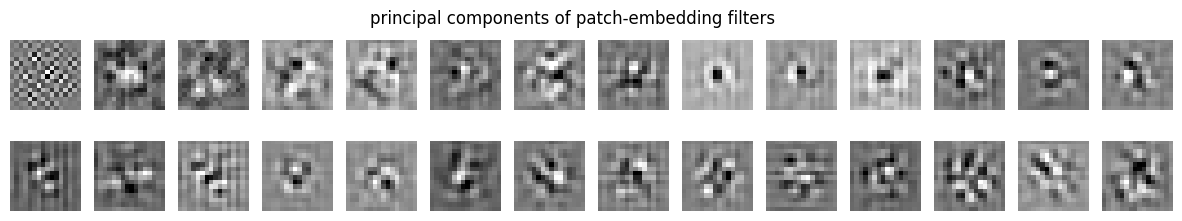

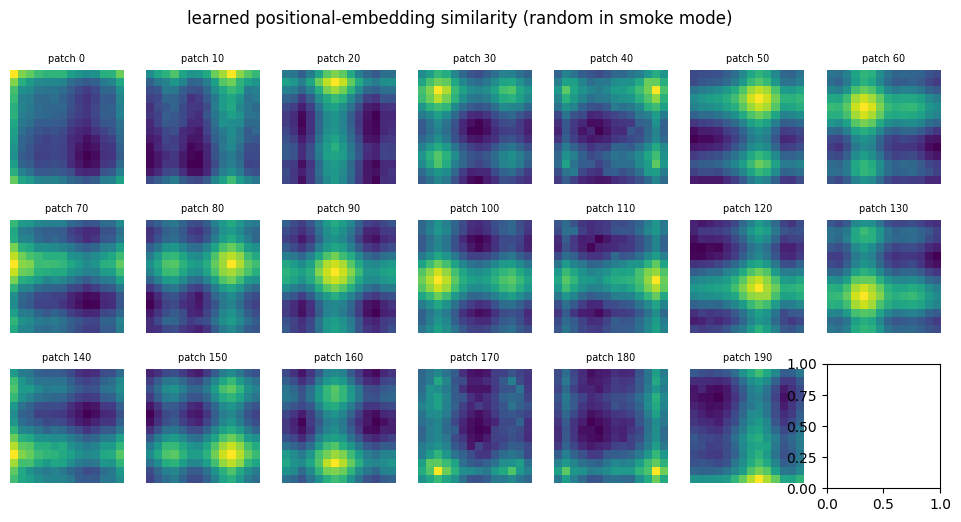

In [4]:
from omari_us.models import build_model
vit = build_model("vit_b16", pretrained=(MODE != "smoke")).eval()
print("init:", vit.init_source, "| params:", f"{sum(p.numel() for p in vit.parameters()):,}")
W = vit.patch_embed.proj.weight.detach().reshape(768, -1)       # (768, 3*16*16)
U, S, Vt = torch.linalg.svd(W - W.mean(0), full_matrices=False)
fig, axes = plt.subplots(2, 14, figsize=(15, 2.4))
for k, ax in enumerate(axes.flat):
    f = Vt[k].reshape(3, 16, 16).mean(0); ax.imshow(f, cmap="gray"); ax.axis("off")
plt.suptitle("principal components of patch-embedding filters"); plt.show()
P = vit.pos_embed.detach()[0, 1:]                                 # (196, 768)
sim = torch.nn.functional.cosine_similarity(P[:, None], P[None], dim=-1)
fig, axes = plt.subplots(3, 7, figsize=(12, 5.5))
for ax, q in zip(axes.flat, range(0, 196, 10)):
    ax.imshow(sim[q].reshape(14, 14), cmap="viridis"); ax.set_title(f"patch {q}", fontsize=7); ax.axis("off")
plt.suptitle("learned positional-embedding similarity (random in smoke mode)"); plt.show()

## Train: frozen encoder (linear probe) and full fine-tuning
Both regimes use the same patient-disjoint splits, class-weighted cross-entropy with label smoothing, cosine schedule with warm-up,
and model selection by **validation macro-F1**. The test split is evaluated once with the selected checkpoint.
Hyper-parameters come from `configs/vit_b16.yaml`; `demo` shortens epochs, `smoke` uses random weights and 2 batches.

In [5]:
from omari_us.training import TrainConfig, train
from omari_us.utils import load_yaml
C = load_yaml(os.path.join(REPO, "configs", "vit_b16.yaml"))
def make_cfg(regime, label_fraction=1.0, seed=0):
    r = dict(C["regimes"][regime])
    cfg = TrainConfig(model="vit_b16", regime=regime, label_fraction=label_fraction, seed=seed, out_dir=RUNS,
                      loss=C["loss"], weight_scheme=C["weight_scheme"], label_smoothing=C["label_smoothing"], patience=C["patience"],
                      input_overrides=C.get("input", {}), augment=C.get("augment", {}), **r)
    if MODE == "demo":
        cfg.epochs = min(cfg.epochs, 4)
    if MODE == "smoke":
        cfg.epochs, cfg.batch_size, cfg.max_train_batches, cfg.max_eval_batches = 2, 4, 2, 2
        cfg.pretrained, cfg.num_workers, cfg.amp = False, 0, False
    return cfg

results = {}
for regime in ["frozen", "finetune"]:
    t0 = time.time()
    results[regime] = train(make_cfg(regime), splits)
    s = results[regime]
    print(f"{regime:9s} best epoch {s['best_epoch']} | val macro-F1 {s['best_val_macro_f1']:.3f} | test macro-F1 {s['test']['macro_f1']:.3f} | {time.time()-t0:.0f}s")

vit_b16_frozen_lf1_s0:   0%|          | 0/15 [00:00<?, ?it/s]

/content/omari-workshop/python/omari_us/training/__init__.py:202: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss) * len(y)


frozen    best epoch 12 | val macro-F1 0.857 | test macro-F1 0.804 | 910s


vit_b16_finetune_lf1_s0:   0%|          | 0/25 [00:00<?, ?it/s]

finetune  best epoch 16 | val macro-F1 0.964 | test macro-F1 0.941 | 1311s


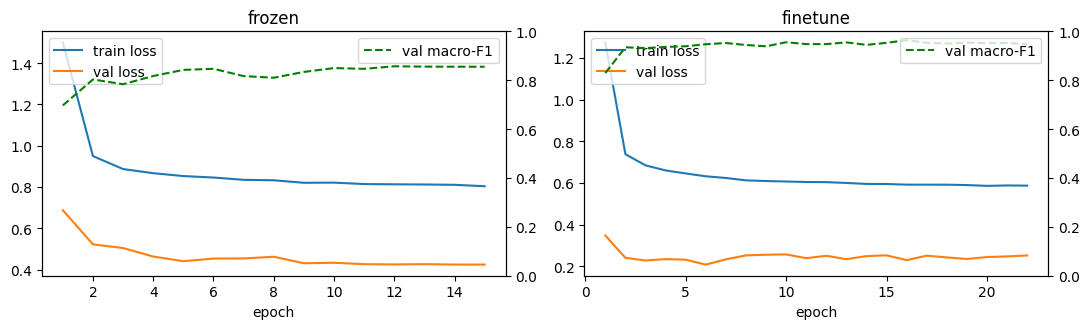

In [6]:
# Learning curves (written to history.json in each run folder)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, regime in zip(axes, ["frozen", "finetune"]):
    h = json.load(open(os.path.join(RUNS, results[regime]["run"], "history.json")))
    ax.plot(h["epoch"], h["train_loss"], label="train loss"); ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax2 = ax.twinx(); ax2.plot(h["epoch"], h["val_macro_f1"], "g--", label="val macro-F1"); ax2.set_ylim(0, 1)
    ax.set_title(regime); ax.set_xlabel("epoch"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [7]:
from omari_us.evaluation import classification_report
z = np.load(os.path.join(RUNS, results["finetune"]["run"], "test_predictions.npz"), allow_pickle=True)
rep = classification_report(z["labels"], z["probs"].argmax(1))
print(f"test accuracy {rep['accuracy']:.3f} | macro-F1 {rep['macro_f1']:.3f} | balanced accuracy {rep['balanced_accuracy']:.3f}")
pd.DataFrame(rep["per_class"], index=CLASS_SHORT).round(3)

test accuracy 0.946 | macro-F1 0.941 | balanced accuracy 0.949


,precision,recall,f1,support
Abdomen,0.868,0.969,0.916,358
Brain,0.990,0.995,0.993,1472
Femur,0.892,0.910,0.901,524
Thorax,0.926,0.927,0.927,660
Cervix,0.995,0.997,0.996,645
Other,0.933,0.896,0.914,1612


### Optional: label-efficiency sweep
Repeats training on patient-level label fractions (1–100%) × seeds. Expensive in `full` mode (18 runs per regime);
notebook 05 collects the `summary.json` files into the website's learning-curve figure.

In [8]:
RUN_LABEL_SWEEP = False  #@param {type:"boolean"}
SWEEP_REGIME = "finetune"  #@param ["frozen", "finetune"]
if RUN_LABEL_SWEEP:
    fracs = C["label_fractions"] if MODE == "full" else [0.05, 0.25, 1.0]
    seeds = C["seeds"] if MODE == "full" else [0]
    for f in fracs:
        for s in seeds:
            r = train(make_cfg(SWEEP_REGIME, f, s), splits, progress=False)
            print(r["run"], round(r["test"]["macro_f1"], 4))

## Attention from the fine-tuned model
timm uses fused scaled-dot-product attention; `omari_us.explainability.vit.capture_attention` turns it off temporarily so the attention
matrices exist, records them with forward hooks, and restores the setting. Remember: attention is routing, not attribution.

torch.Size([12, 12, 197, 197]) rows sum to 1: True


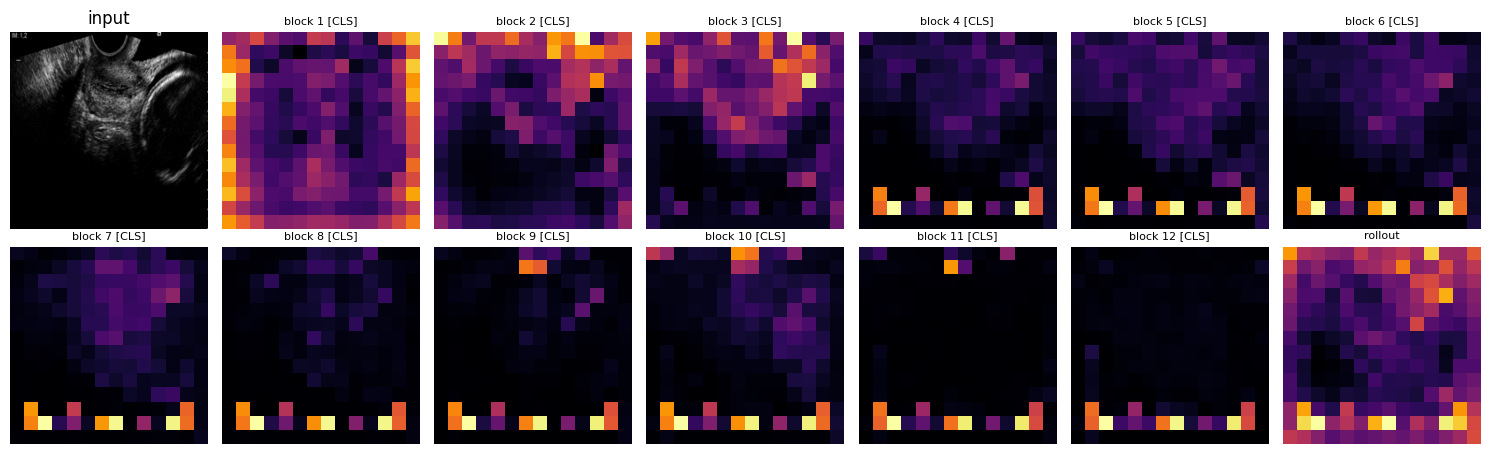

In [9]:
from omari_us.models import load_finetuned
from omari_us.datasets import input_spec, build_transforms
from omari_us.explainability import vit as vitx
from PIL import Image
ft, _ = load_finetuned("vit_b16", os.path.join(RUNS, results["finetune"]["run"], "best.pt"))
row = splits[splits.split == "test"].iloc[0]
im = Image.open(row.path).convert("L")
x = build_transforms(input_spec("vit_b16"), False)(im).unsqueeze(0)
A = vitx.attention_maps(ft, x)                 # (12 blocks, 12 heads, 197, 197)
print(A.shape, "rows sum to 1:", torch.allclose(A.sum(-1), torch.ones_like(A.sum(-1)), atol=1e-4))
fig, axes = plt.subplots(2, 7, figsize=(15, 4.6))
axes[0, 0].imshow(im.resize((224, 224)), cmap="gray"); axes[0, 0].set_title("input"); axes[0, 0].axis("off")
for b, ax in zip(range(12), list(axes.flat)[1:13]):
    ax.imshow(A[b, :, 0, 1:].mean(0).reshape(14, 14), cmap="inferno"); ax.set_title(f"block {b+1} [CLS]", fontsize=8); ax.axis("off")
ax = list(axes.flat)[13]; ax.imshow(vitx.attention_rollout(ft, x), cmap="inferno"); ax.set_title("rollout", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## References
- Burgos-Artizzu X.P. et al. *Evaluation of deep convolutional neural networks for automatic classification of common maternal fetal ultrasound planes.* Sci. Rep. 10, 10200 (2020). Dataset: Zenodo 3904280, CC BY 4.0.
- Huang G. et al. *Densely connected convolutional networks.* CVPR 2017.
- Dosovitskiy A. et al. *An image is worth 16×16 words.* ICLR 2021; Steiner A. et al. *How to train your ViT?* TMLR 2022.
- He K. et al. *Masked autoencoders are scalable vision learners.* CVPR 2022.
- Megahed Y. et al. *USF-MAE: Ultrasound self-supervised foundation model with masked autoencoding.* Biomed. Signal Process. Control 122, 110313 (2026). https://github.com/Yusufii9/USF-MAE
- Zhou B. et al. CAM, CVPR 2016 · Selvaraju R.R. et al. Grad-CAM, ICCV 2017 · Chattopadhay A. et al. Grad-CAM++, WACV 2018 · Abnar & Zuidema, attention rollout, ACL 2020 · Chefer H. et al., CVPR 2021 · Adebayo J. et al., sanity checks, NeurIPS 2018 · Petsiuk V. et al., RISE / deletion–insertion, BMVC 2018 · Guo C. et al., calibration, ICML 2017.